In [7]:
from HBC import HBC, add_adjusted_stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

from src.utils.util import set_labels
from notebooks.figures.extinction_compare_metrics import stat_dict

plt.style.use('seaborn-v0_8-paper')

In [8]:
comparisons = [
    ('control_open', 'truth'),
    ('control_periodic', 'truth'),
    ('open', 'truth'),
    ('periodic', 'truth'),
    ('control_open', 'control_periodic'),
    ('periodic', 'open')
]


In [9]:
lens = [5, 7, 9, 11, 15, 19]
cloud_field = 'TradeCumulus'
# cloud_field = 'Transition'
periodic_bases = [f'/data/keeling/a/johntl3/b/Synthetic/IO/thesis_periodic_V2/{cloud_field}/len{l:03d}/ex00' for l in lens]
open_bases = [f'/data/keeling/a/johntl3/b/Synthetic/IO/thesis/{cloud_field}/len{l:03d}/ex00' for l in lens]
df = []
for pb, ob in zip(periodic_bases, open_bases):
    h = HBC(pb, ob)
    df.append(h.calc_stats(comparisons, stat_dict))
df = pd.concat(df)

df, report = add_adjusted_stats(df)

if report:
    print(f"{len(report)} issue(s) found:")
    for msg in report:
        print(" -", msg)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/l

In [10]:
df

,open_source,periodic_source,R,T,r1_name,r2_name,stat_name,stat,R-T
0,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,4.0,0.0,control_open,truth,Relative Bias (%),inf,4.0
1,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,4.0,0.0,control_open,truth,Relative RMSD (%),inf,4.0
2,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,4.0,0.0,control_open,truth,Relative Bias Intersection (%),NaN,4.0
3,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,4.0,0.0,control_open,truth,Relative RMSD Intersection (%),NaN,4.0
4,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,4.0,0.0,control_open,truth,Jaccard Index,0.000000,4.0
...,...,...,...,...,...,...,...,...,...
1435,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,18.0,16.0,periodic,control_periodic,adjusted Relative Bias Intersection (%),2.832621,2.0
1436,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,18.0,16.0,open,control_open,adjusted Relative RMSD (%),18.508247,2.0
1437,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,18.0,16.0,periodic,control_periodic,adjusted Relative RMSD (%),28.699451,2.0
1438,/data/keeling/a/johntl3/b/Synthetic/IO/thesis/...,/data/keeling/a/johntl3/b/Synthetic/IO/thesis_...,18.0,16.0,open,control_open,adjusted Relative RMSD Intersection (%),10.562546,2.0


In [11]:
def plot_r1_and_r2(df, r1_name, r2_name, x_axis='T', stat_list=None, ax=None):
    sub = df[(df['r1_name'] == r1_name) & (df['r2_name'] == r2_name)]
    if stat_list is None:
        stat_list = sub['stat_name'].unique()
    if ax is None:
        f, ax = plt.subplots(1, len(stat_list), figsize=(5*len(stat_list),5))
    for i, s in enumerate(stat_list):
        sub[(sub['stat_name'] == s)].pivot(columns='R',values='stat',index=x_axis).plot(marker='o', ax=ax[i])
        ax[i].grid()
        ax[i].set_ylabel(s)
        ax[i].set_title(s)
    plt.suptitle(f'R1 = {r1_name}, R2 = {r2_name}')

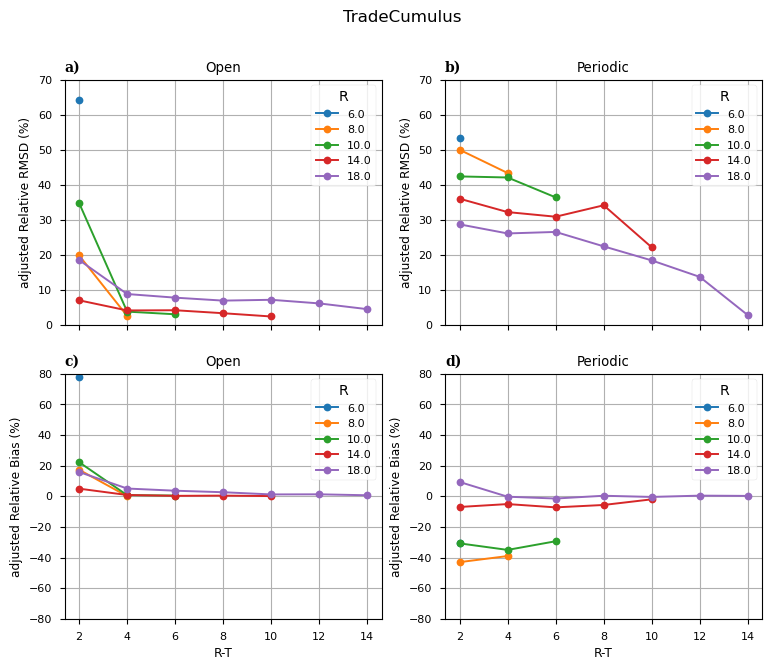

In [12]:
x_axis = 'R-T'
f, ax = plt.subplots(2, 2, figsize=(9,7), sharex=True, sharey=False)
plot_r1_and_r2(
    df=df[(df['T'] >= 4) & (df['R'] >= 6)],
    r1_name='open',
    r2_name='control_open',
    x_axis=x_axis,
    stat_list=['adjusted Relative RMSD (%)', 'adjusted Relative Bias (%)'],
    ax=ax[:,0]
)
plot_r1_and_r2(
    df=df[(df['T'] >= 4) & (df['R'] >= 6)],
    r1_name='periodic',
    r2_name='control_periodic',
    x_axis=x_axis,
    stat_list=['adjusted Relative RMSD (%)', 'adjusted Relative Bias (%)'],
    ax=ax[:,1]
)
ax[0,0].set_title('Open')
ax[1,0].set_title('Open')
ax[0,1].set_title('Periodic')
ax[1,1].set_title('Periodic')
f.suptitle(cloud_field)

# Trade Cumulus Settings
if(cloud_field == 'TradeCumulus'):
    ax[0,0].set_ylim([0, 70])
    ax[0,1].set_ylim([0, 70])
    ax[1,0].set_ylim([-80, 80])
    ax[1,1].set_ylim([-80, 80])

# Transition settings
if(cloud_field == 'Transition'):
    ax[0,0].set_ylim([0, 130])
    ax[0,1].set_ylim([0, 130])
    ax[1,0].set_ylim([-125, 125])
    ax[1,1].set_ylim([-125, 125])

set_labels(ax.flatten())

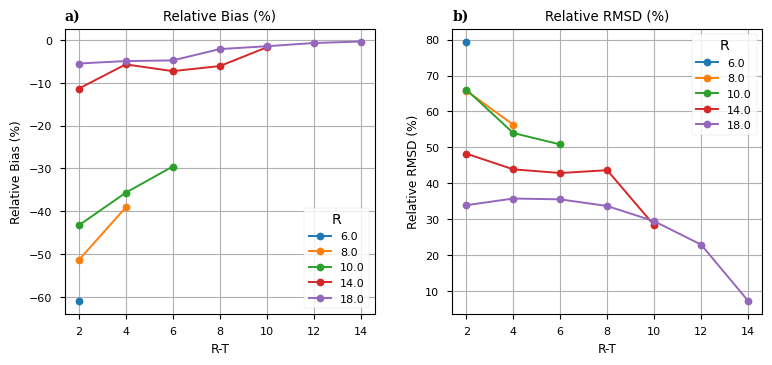

In [24]:
def plot_r1_and_r2_single(df, r1_name, r2_name, x_axis='T', stat_name=None, ax=None):
    sub = df[(df['r1_name'] == r1_name) & (df['r2_name'] == r2_name)]
    if ax is None:
        f, ax = plt.subplots(1, 1, figsize=(5,5))
    sub[(sub['stat_name'] == stat_name)].pivot(columns='R',values='stat',index=x_axis).plot(marker='o', ax=ax)
    ax.grid()
    ax.set_ylabel(stat_name)
    ax.set_title(stat_name)
    # plt.suptitle(f'R1 = {r1_name}, R2 = {r2_name}')

plot_kwargs = {
    'df': df[(df['T'] >= 4) & (df['R'] >= 6)],
    'r1_name': 'periodic',
    'r2_name': 'open',
    'x_axis': 'R-T'
}

f, ax = plt.subplots(1, 2, figsize=(9,3.5), sharex=True, sharey=False)
f.subplots_adjust(hspace=0.3, wspace=0.25, top=0.925)
plot_r1_and_r2_single(stat_name='Relative Bias (%)', ax=ax[0], **plot_kwargs)
plot_r1_and_r2_single(stat_name='Relative RMSD (%)', ax=ax[1], **plot_kwargs)
# plot_r1_and_r2_single(stat_name='Relative Bias Intersection (%)', ax=ax[0,1], **plot_kwargs)
# plot_r1_and_r2_single(stat_name='Relative RMSD Intersection (%)', ax=ax[1,1], **plot_kwargs)
# plot_r1_and_r2_single(stat_name='Inverse Jaccard', ax=ax[2,0], **plot_kwargs)
# plot_r1_and_r2_single(stat_name='Jaccard Index', ax=ax[2,1], **plot_kwargs)

r1 = plot_kwargs['r1_name']
r2 = plot_kwargs['r2_name']
# f.suptitle(f'{cloud_field}\nR1 = {r1}, R2 = {r2}')

set_labels(ax.flatten())

# # Trade Cumulus Settings
# if(cloud_field == 'TradeCumulus'):
#     ax[0,0].set_ylim([0, 125])
#     ax[0,1].set_ylim([0, 125])
#     ax[1,0].set_ylim([-80, 80])
#     ax[1,1].set_ylim([-80, 80])

# # Transition settings
# if(cloud_field == 'Transition'):
#     ax[0,0].set_ylim([0, 145])
#     ax[0,1].set_ylim([0, 145])
#     ax[1,0].set_ylim([-60, 60])
#     ax[1,1].set_ylim([-60, 60])


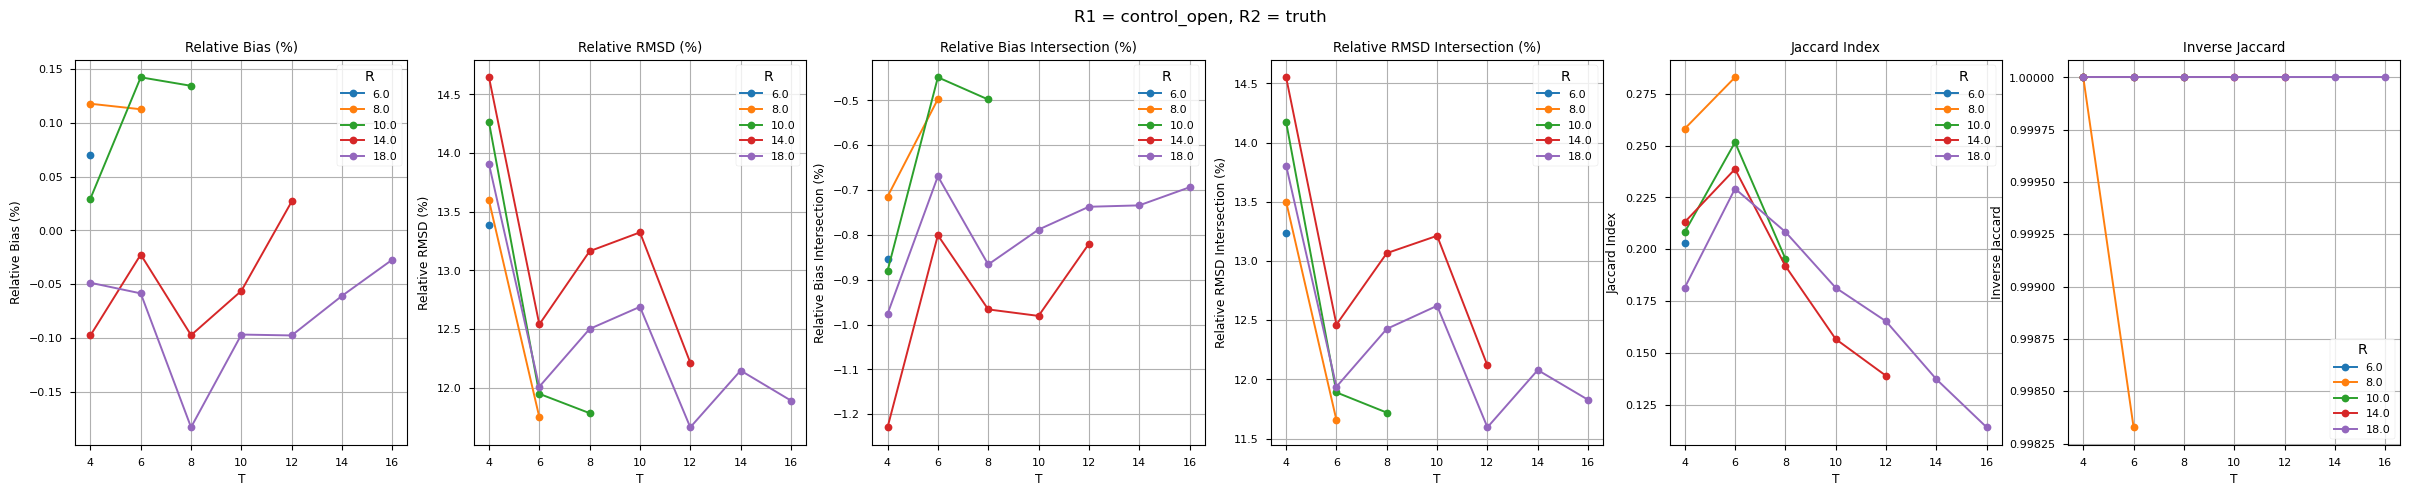

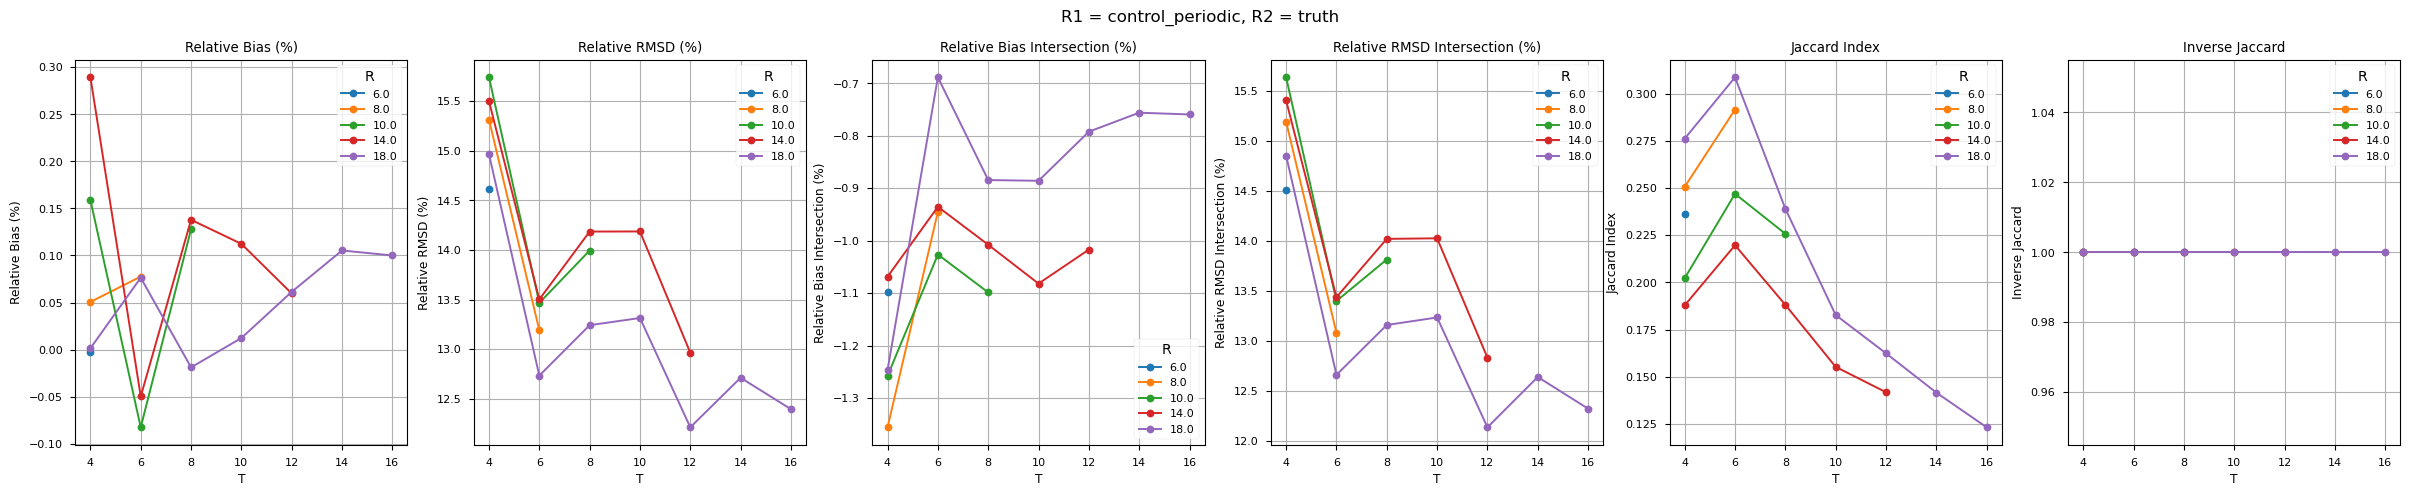

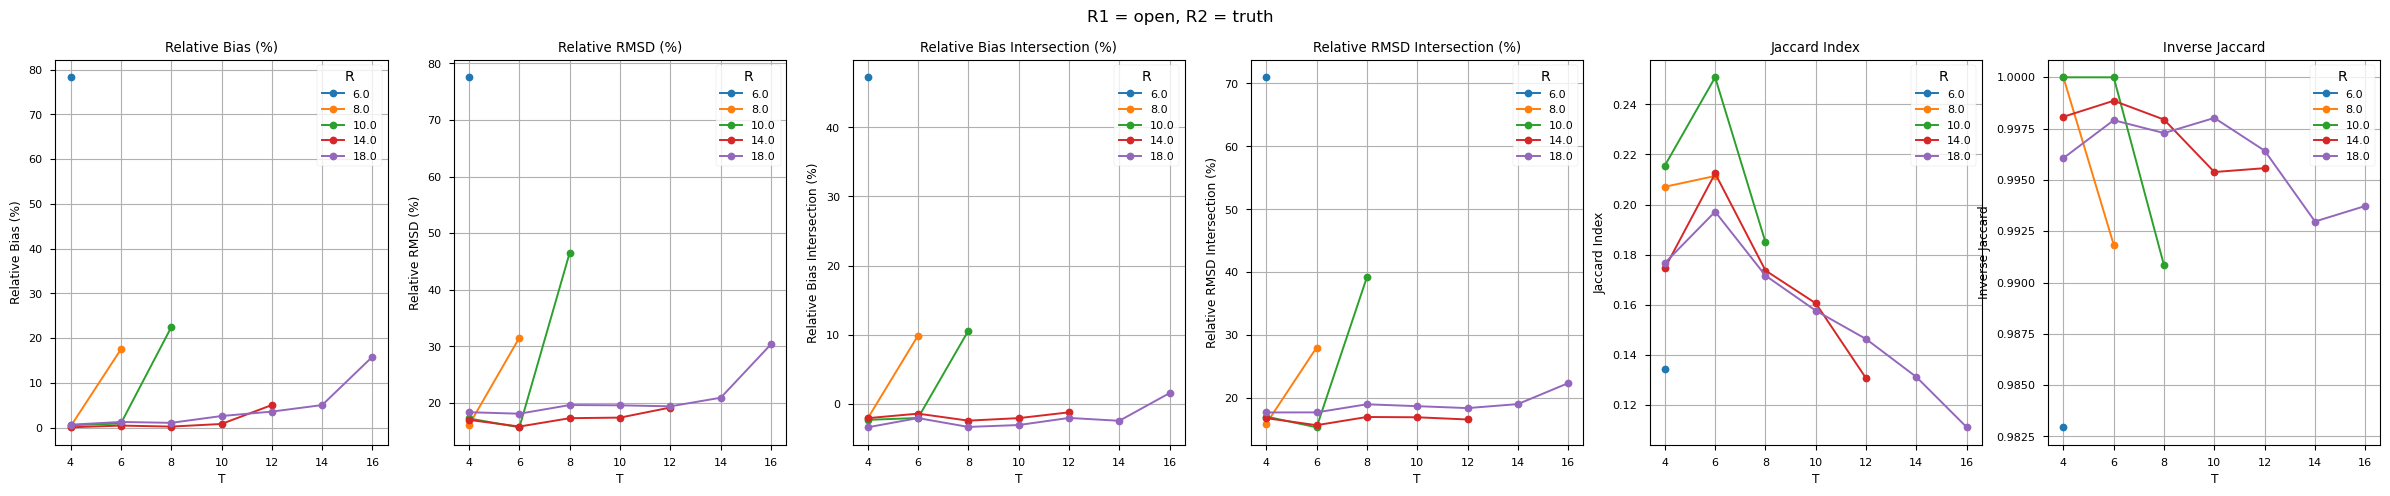

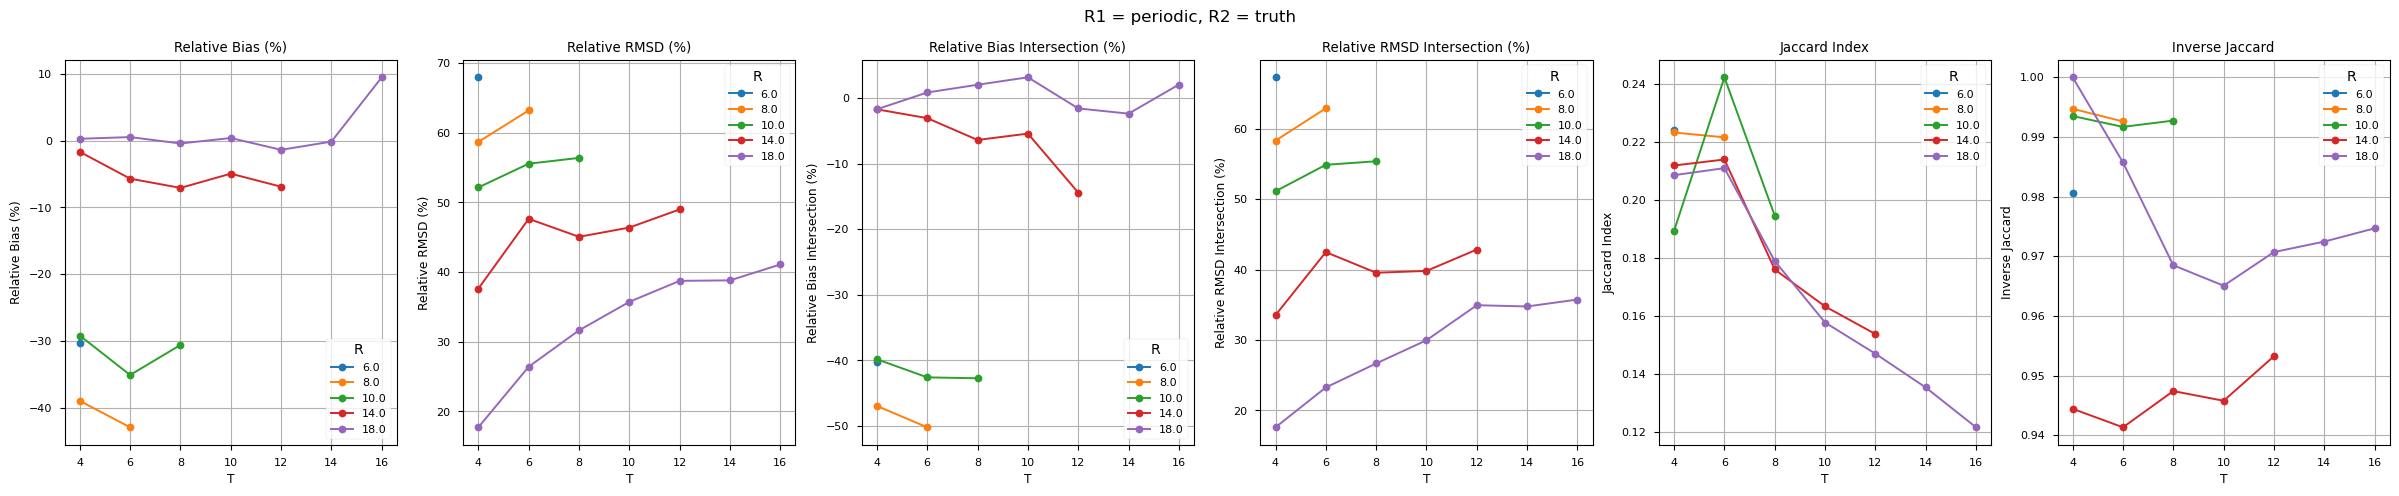

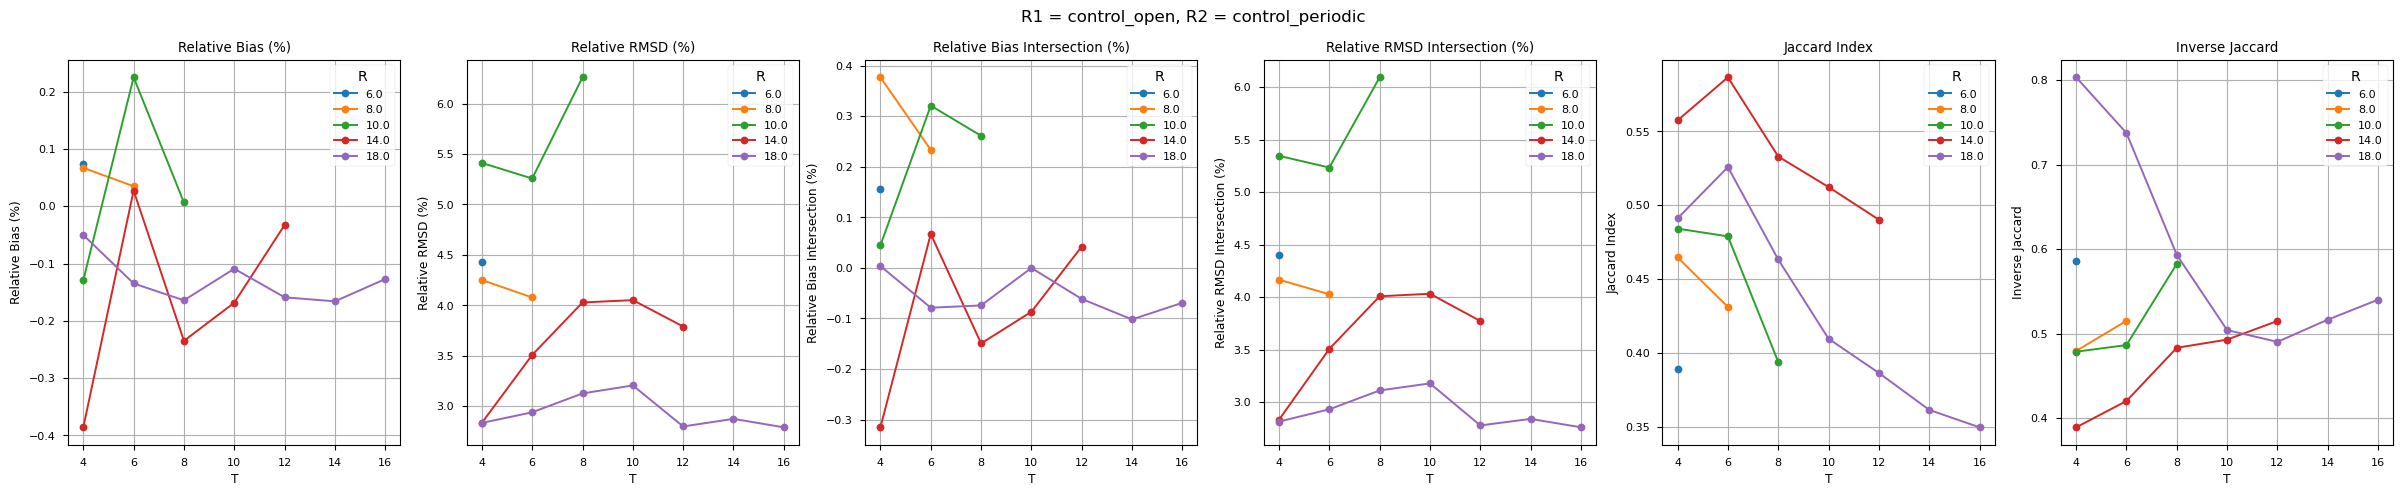

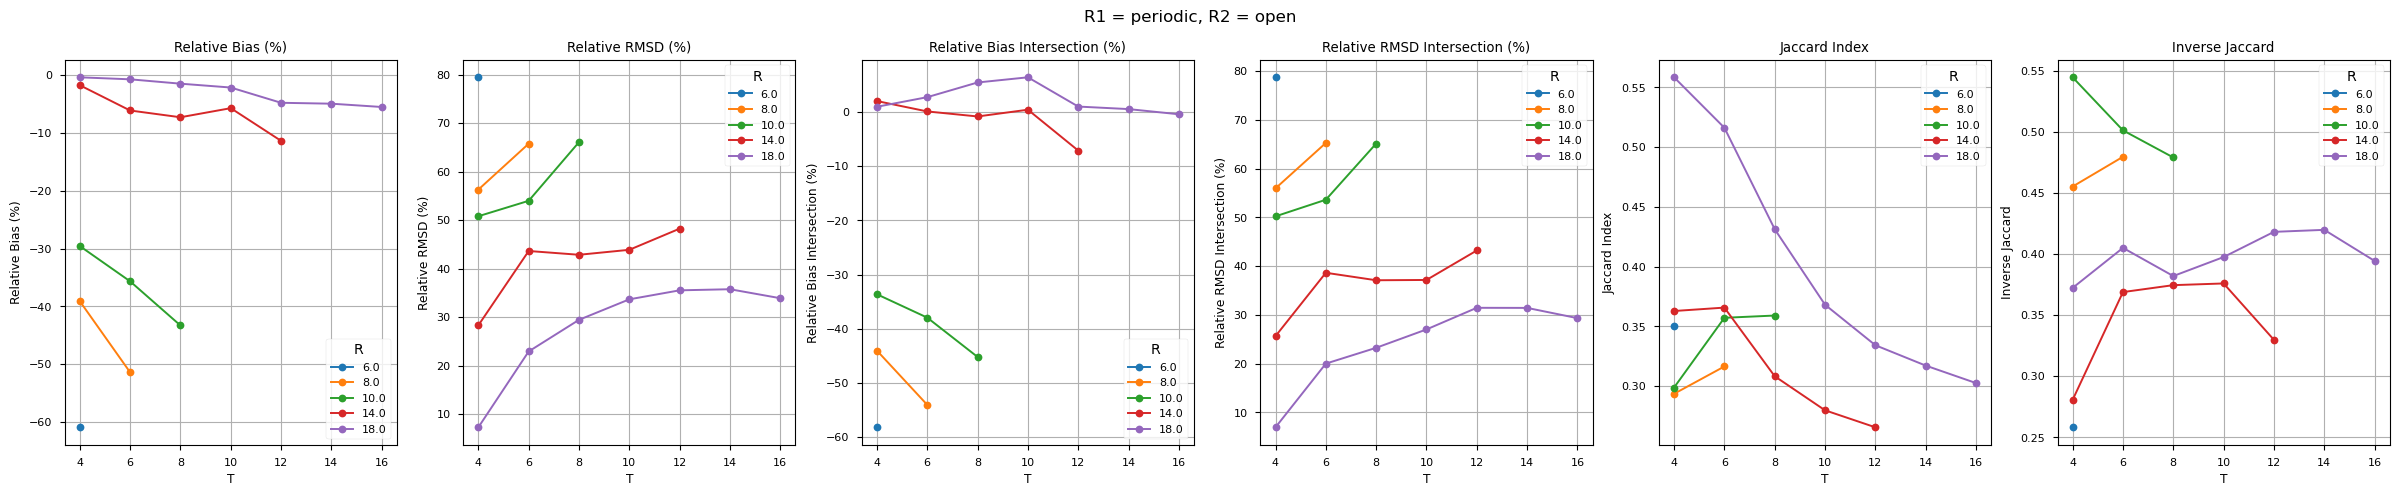

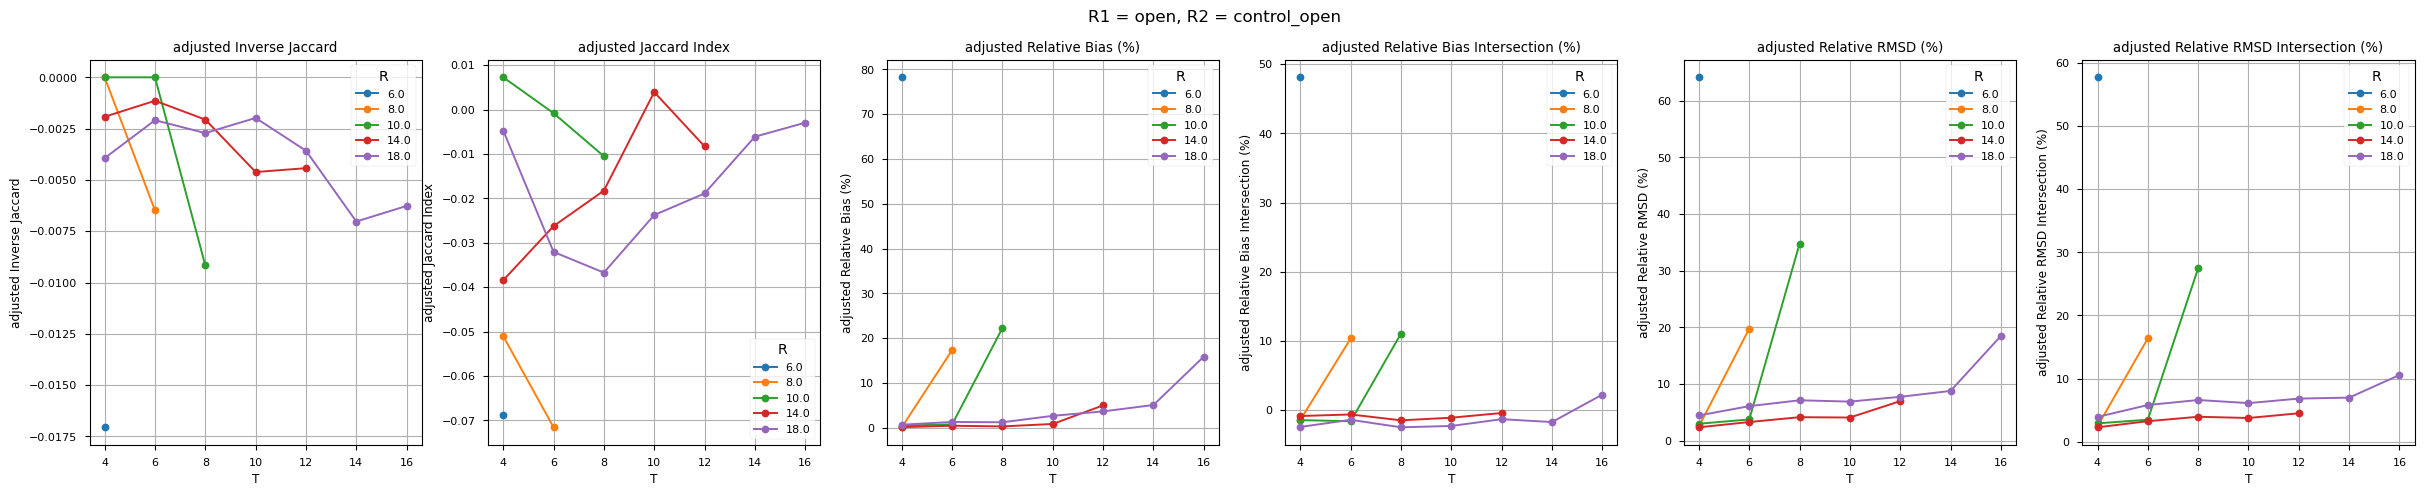

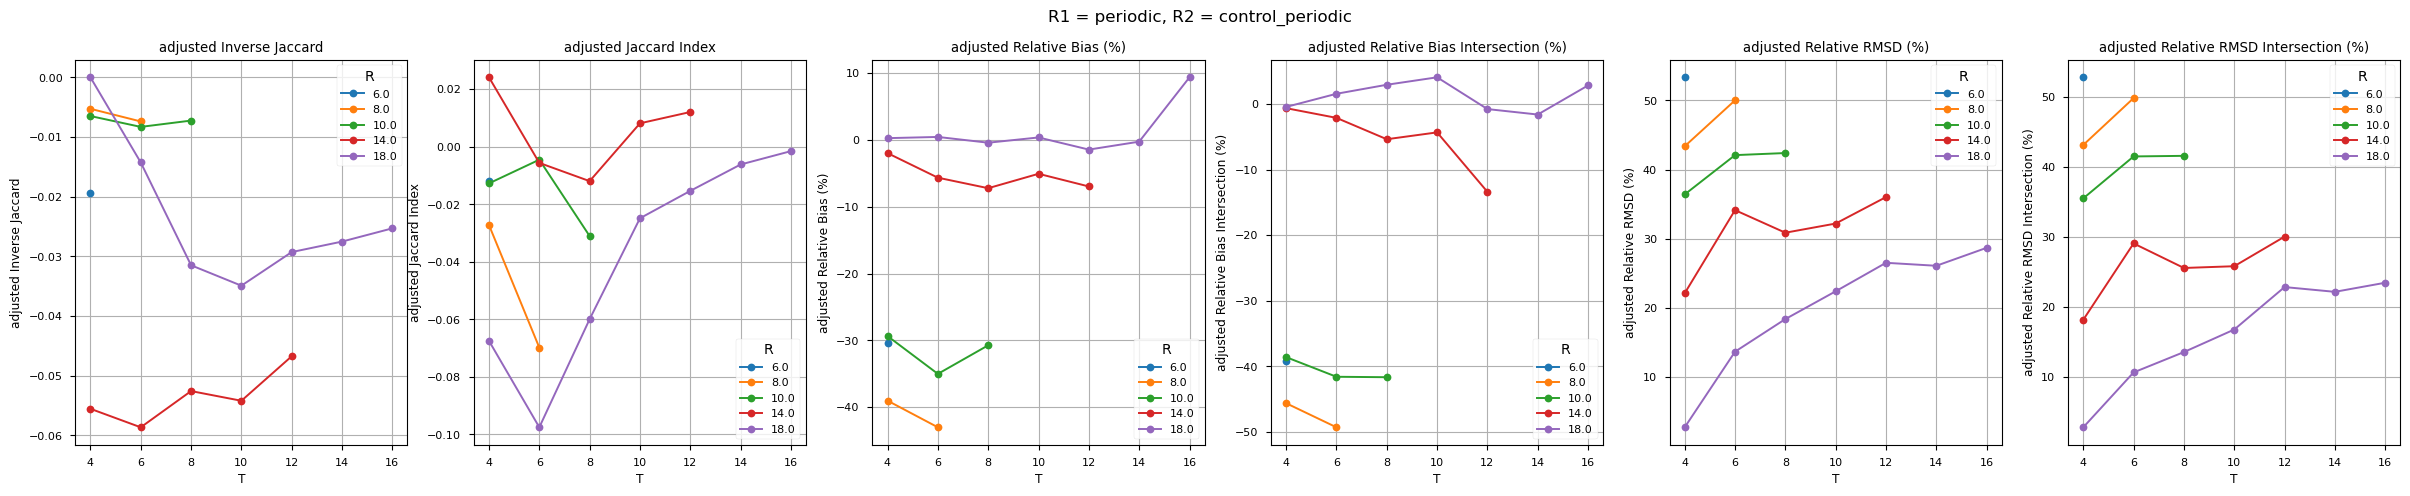

In [15]:
r1r2pairs = comparisons.copy()
r1r2pairs.append(('open', 'control_open'))
r1r2pairs.append(('periodic', 'control_periodic'))

for r1_tmp, r2_tmp in r1r2pairs:
    plot_r1_and_r2(df[(df['T'] >= 4) & (df['R'] >= 6)], r1_tmp, r2_tmp, x_axis='T')

In [ ]:
# plot_kwargs = {
#     'y':'z',
#     'vmin': 0,
#     'vmax': 27,
#     'cmap': 'gist_heat_r'
# }
# diff_kwargs = {
#     'y':'z',
#     'vmin': -5,
#     'vmax': 5,
#     'cmap': 'RdBu_r'
# }

# xi = 1
# for xi in range(h.ext.dims['x']):
#     tmp = h.ext.isel(x=xi).copy(deep=True)
#     f, ax = plt.subplots(2, 3, figsize=(15,6), sharex=True, sharey=True)
#     tmp.open.plot(ax=ax[0,0], **plot_kwargs)
#     tmp.truth.plot(ax=ax[0,1], **plot_kwargs)
#     tmp.periodic.plot(ax=ax[0,2], **plot_kwargs)
#     ax[0,0].set_title('open')
#     ax[0,1].set_title('truth')
#     ax[0,2].set_title('periodic')

#     (tmp.open - tmp.truth).plot(ax=ax[1,0], **diff_kwargs)
#     (tmp.periodic - tmp.open).plot(ax=ax[1,1], **diff_kwargs)
#     (tmp.periodic - tmp.truth).plot(ax=ax[1,2], **diff_kwargs)
#     ax[1,0].set_title('open - truth')
#     ax[1,1].set_title('periodic - open')
#     ax[1,2].set_title('periodic - truth')
#     f.suptitle(f'x = {tmp.x.data}')

In [ ]:
print(f'solar zenith: {np.degrees(np.arccos(h.solver_periodic[0.67].source.solarmu.data))}')
print(f'solar azimuth: {np.degrees(h.solver_periodic[0.67].source.solaraz.data)}')

In [ ]:
for i in range(9):
    tmp_z = h.sensor_true['MISR']['sensor_list'][i].projection_zenith
    tmp_a = h.sensor_true['MISR']['sensor_list'][i].projection_azimuth
    print(f'i:{i} | zenith = {tmp_z} | azimuth = {tmp_a}')